<a href="https://colab.research.google.com/github/iliyadindar/DEEP/blob/main/week7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Sinüs Dalgası Oluşturma ve Görselleştirme Kodları

Öncelikle gerekli kütüphaneleri (`numpy` ve `matplotlib`) içe aktarıyoruz. Ardından, verdiğiniz parametrelere göre sinüs dalgası üreten fonksiyonumuzu tanımlayıp, 2'nin kuvveti uzunluğunda bir zaman vektörü oluşturarak dalgayı çizdiriyoruz.

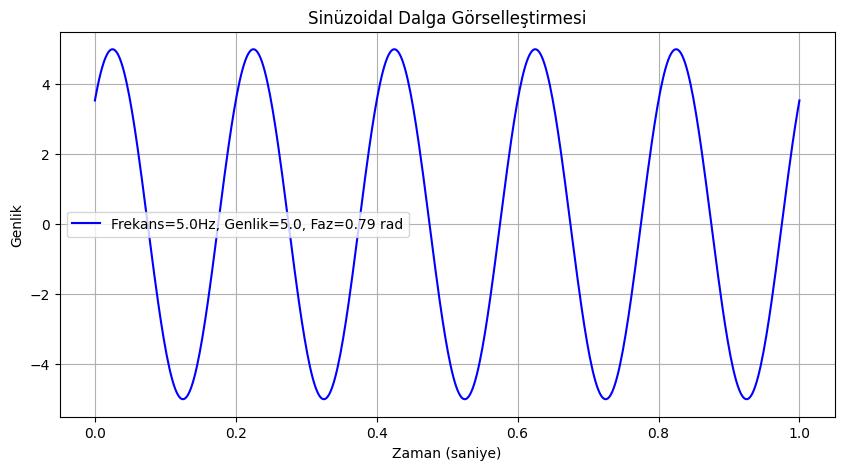

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def sinus_dalgasi_uret(t_vektoru, genlik, frekans, faz):
    # Formül: y = Genlik * sin(2 * pi * Frekans * t + Faz)
    sinus_vektoru = genlik * np.sin(2 * np.pi * frekans * t_vektoru + faz)
    return sinus_vektoru

N = 512
t_vektoru = np.linspace(0, 1, N) # 0 ile 1 saniye arasında 512 eşit nokta

genlik = 5.0      # Dalganın maksimum yüksekliği
frekans = 5.0     # 1 saniyede tekrarlanan dalga sayısı (Periyot T = 1/5 = 0.2 saniye)
faz = np.pi / 4   # Radyan cinsinden faz kayması (45 derece)

# Fonksiyonu çağırarak sinüs değerlerini elde ediyoruz
sinus_sinyali = sinus_dalgasi_uret(t_vektoru, genlik, frekans, faz)

# Görselleştirme
plt.figure(figsize=(10, 5))
plt.plot(t_vektoru, sinus_sinyali, label=f'Frekans={frekans}Hz, Genlik={genlik}, Faz={faz:.2f} rad', color='blue')
plt.title('Sinüzoidal Dalga Görselleştirmesi')
plt.xlabel('Zaman (saniye)')
plt.ylabel('Genlik')
plt.grid(True)
plt.legend()
plt.show()

### Kodların Satır Satır Açıklaması



* **`N = 512`**: Soruda belirtilen 2'nin kuvveti kuralına uymak için $2^9 = 512$ boyutunda bir uzunluk seçiyoruz.
* **`np.linspace(0, 1, N)`**: 0 ile 1 saniye arasında, eşit aralıklı 512 adet zaman noktası (vektör) oluşturur.
* **`plt.plot(t_vektoru, sinus_sinyali, ...)`**: X eksenine zamanı, Y eksenine ise hesapladığımız sinüs değerlerini koyarak dalgayı çizdirir.
* **`plt.grid(True)`**: Grafiğin daha rahat okunabilmesi için arka plana ızgara çizgileri ekler.

### 2. Sinyale Gürültü Ekleme Fonksiyonu ve Görselleştirme

Bu bölümde, mevcut sinyalimize belirlediğimiz oranda rastgele gürültü ekleyen fonksiyonu tanımlayıp grafiğe dökeceğiz.

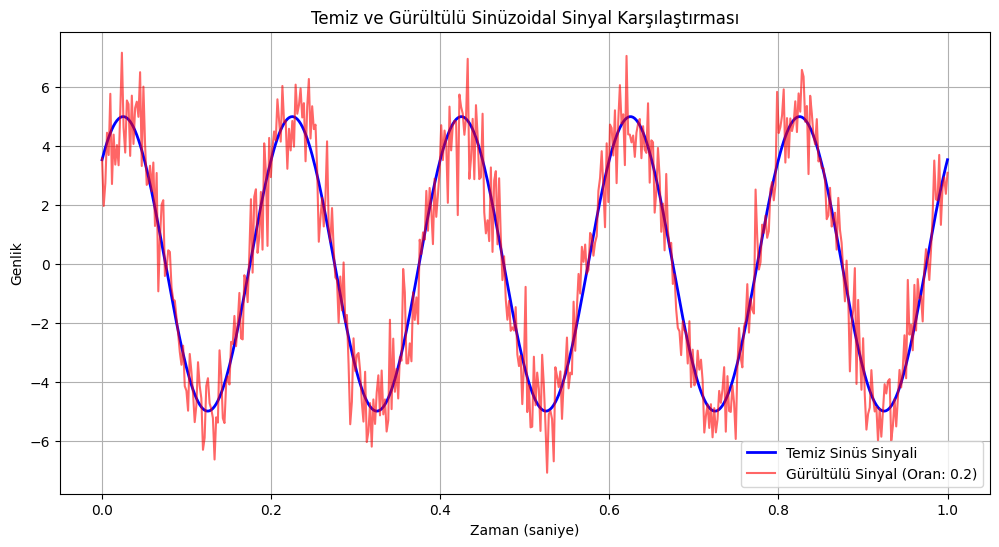

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def gurultu_ekle(vektor, gurultu_orani, genlik):
    # 1. Adım: Sinyal ile aynı boyutta rastgele gürültü üretiyoruz (Gauss Dağılımı)
    # Gürültünün şiddetini (standart sapmasını) 'genlik * gurultu_orani' ile kontrol ediyoruz
    standart_sapma = genlik * gurultu_orani
    gurultu = np.random.normal(0, standart_sapma, len(vektor))

    # 2. Adım: Orijinal vektör ile gürültüyü topluyoruz
    gurultulu_vektor = vektor + gurultu
    return gurultulu_vektor

# Gürültü oranını belirliyoruz (Örn: %20 gürültü için 0.2)
gurultu_orani = 0.2  # [0, 1] aralığında

# Fonksiyonu kullanarak gürültülü sinyali üretiyoruz
# (Bir önceki adımda ürettiğimiz 'sinus_sinyali' ve 'genlik' değişkenlerini kullanıyoruz)
gurultulu_sinyal = gurultu_ekle(sinus_sinyali, gurultu_orani, genlik)

# Temiz ve Gürültülü Sinyalleri Karşılaştırmalı Görselleştirme
plt.figure(figsize=(12, 6))
plt.plot(t_vektoru, sinus_sinyali, label='Temiz Sinüs Sinyali', color='blue', linewidth=2)
plt.plot(t_vektoru, gurultulu_sinyal, label=f'Gürültülü Sinyal (Oran: {gurultu_orani})', color='red', alpha=0.6)
plt.title('Temiz ve Gürültülü Sinüzoidal Sinyal Karşılaştırması')
plt.xlabel('Zaman (saniye)')
plt.ylabel('Genlik')
plt.grid(True)
plt.legend()
plt.show()

### İkinci Adım Kodlarının Satır Satır Açıklaması

* **`np.random.normal(0, standart_sapma, len(vektor))`**: Ortalama değeri `0`, standart sapması (yayılımı/şiddeti) `standart_sapma` olan ve orijinal vektörümüzle aynı sayıda elemana sahip rastgele sayılar üretir. Bu sayılar sinyale eklenecek olan gürültüdür.
* **`standart_sapma = genlik * gurultu_orani`**: Gürültünün gücünü, sinyalin kendi maksimum genliği ile ilişkilendiriyoruz. Böylece genlik büyüdükçe gürültü de onunla orantılı olarak ölçeklenir.
* **`gurultulu_vektor = vektor + gurultu`**: Orijinal sinüs değerlerinin üzerine ürettiğimiz rastgele gürültü değerlerini nokta bazında ekliyoruz.
* **`alpha=0.6`**: Görselleştirmede gürültülü sinyalin çizgi şeffaflığını ayarlayarak arkadaki temiz sinyalin de rahatça seçilebilmesini sağlar.

### 3. Gauss ve Medyan Filtreleri ile Gürültü Temizleme

Gürültülü sinyalimizi temizlemek için iki filtre uygulayacağız:
1. **Gauss Filtresi:** Sinyaldeki ardışık noktaları ağırlıklı ortalama yöntemiyle düzleştirir. Genellikle beyaz gürültüyü (Gaussian noise) azaltmada etkilidir.
2. **Medyan Filtresi:** Belirli bir pencere genişliğindeki değerlerin ortancasını (medyanını) alır. Sinyaldeki ani gürültü sıçramalarını (tuz-biber gürültüsü vb.) temizlemede oldukça başarılıdır.

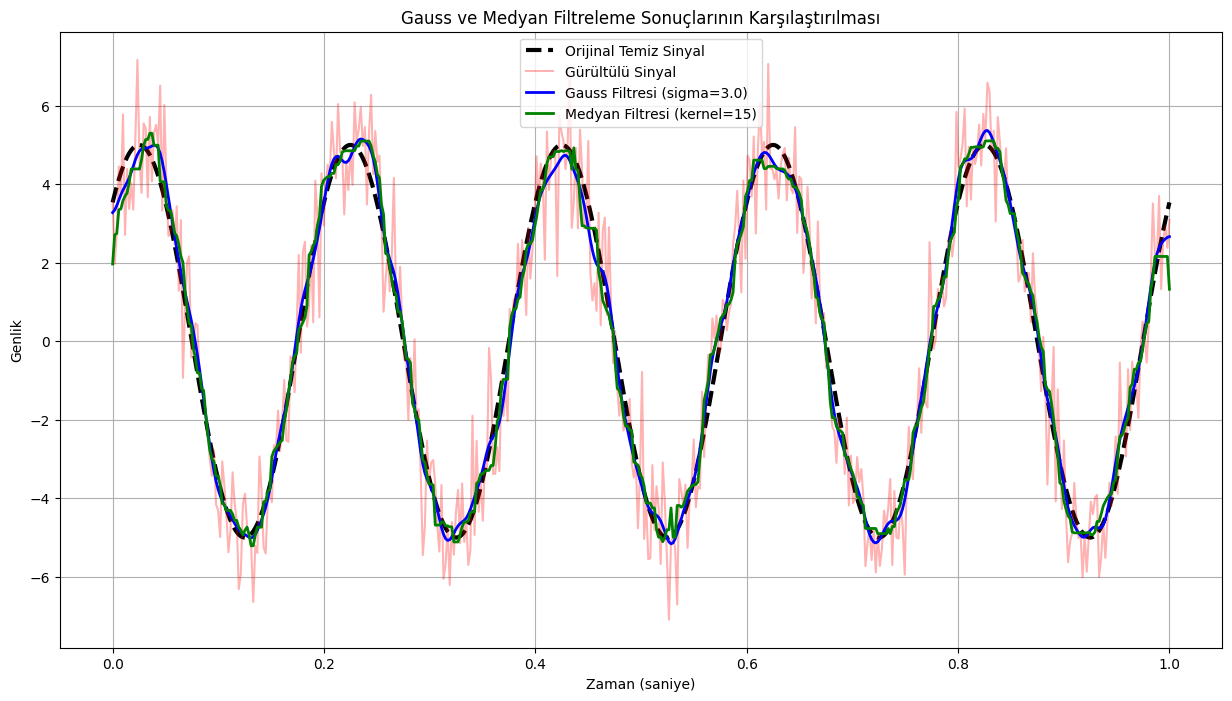

In [7]:
from scipy.ndimage import gaussian_filter1d
from scipy.signal import medfilt

# 1. Gauss Filtresi Uygulaması
# sigma parametresi filtre genişliğini/yumuşatma derecesini belirler
sigma_degeri = 3.0
sinyal_gauss = gaussian_filter1d(gurultulu_sinyal, sigma=sigma_degeri)

# 2. Medyan Filtresi Uygulaması
# kernel_size parametresi tek sayı olmalıdır
pencere_boyutu = 15
sinyal_medyan = medfilt(gurultulu_sinyal, kernel_size=pencere_boyutu)

# Sonuçların Karşılaştırmalı Görselleştirilmesi
plt.figure(figsize=(15, 8))

# Orijinal Temiz Sinyal (Referans)
plt.plot(t_vektoru, sinus_sinyali, label='Orijinal Temiz Sinyal', color='black', linewidth=3, linestyle='--')

# Gürültülü Sinyal
plt.plot(t_vektoru, gurultulu_sinyal, label='Gürültülü Sinyal', color='red', alpha=0.3)

# Gauss Filtre Sonucu
plt.plot(t_vektoru, sinyal_gauss, label=f'Gauss Filtresi (sigma={sigma_degeri})', color='blue', linewidth=2)

# Medyan Filtre Sonucu
plt.plot(t_vektoru, sinyal_medyan, label=f'Medyan Filtresi (kernel={pencere_boyutu})', color='green', linewidth=2)

plt.title('Gauss ve Medyan Filtreleme Sonuçlarının Karşılaştırılması')
plt.xlabel('Zaman (saniye)')
plt.ylabel('Genlik')
plt.grid(True)
plt.legend()
plt.show()

### Filtreleme Sonuçlarının Yorumu

* **Gauss Filtresi:** Rastgele Gauss gürültüsünü sönümlemede son derece başarılı olmuştur. Seçilen `sigma=3.0` parametresi ile sinyal oldukça pürüzsüz hale gelmiş ve orijinal temiz sinüs dalgasına oldukça yaklaşmıştır. Ancak filtreleme doğası gereği dalga tepelerinde hafif bir genlik kaybına (yumuşamaya) sebep olabilir.
* **Medyan Filtresi:** Sinyaldeki gürültü piklerini büyük ölçüde engellemiş olsa da, sinüsün tepe ve çukur bölgelerinde basamak benzeri pürüzler bırakmıştır. Medyan filtresi genellikle doğrusal olmayan ani gürültülerde daha iyi sonuç verirken, bu tarz sürekli Gauss gürültülerinde düzleştirme (Gauss/Hareketli Ortalama) filtreleri kadar pürüzsüz bir sonuç vermeyebilir.

### 4. Ayrık Fourier Dönüşümü (DFT) ile Frekans Analizi

Bu bölümde, dışarıdan kütüphane fonksiyonu (örn. `np.fft.fft`) çağırmadan, doğrudan DFT formülünü ($X[k] = \sum_{n=0}^{N-1} x[n] e^{-j 2 \pi k n / N}$) kullanarak bir fonksiyon yazacağız ve sinyallerimizi analiz edeceğiz.

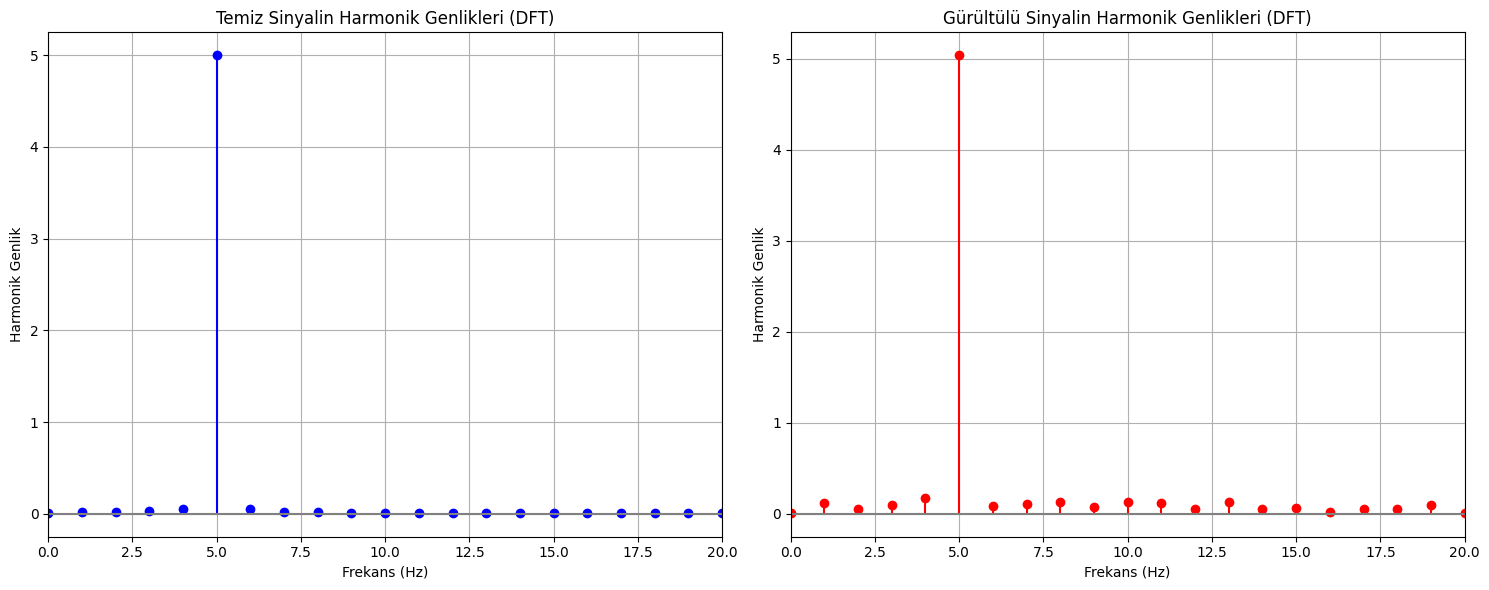

In [8]:
import numpy as np
import matplotlib.pyplot as plt

def dft_ve_harmonik_uret(sinyal):
    N = len(sinyal)
    # N'in 2'nin kuvveti olup olmadığını kontrol edelim
    assert (N & (N - 1)) == 0, "Vektör uzunluğu 2'nin kuvveti olmalıdır!"

    # DFT matrisel veya döngüsel hesaplama (Vektörize yöntem)
    n = np.arange(N)
    k = n.reshape((N, 1))
    ustel_terim = np.exp(-2j * np.pi * k * n / N)

    # DFT Katsayıları (Kompleks değerler)
    dft_katsayilari = np.dot(ustel_terim, sinyal)

    # Harmonik vektörü (Genlik spektrumu)
    # Çift taraflı spektrumu tek taraflıya normalize ederek dönüştürüyoruz
    harmonik_vektoru = (2.0 / N) * np.abs(dft_katsayilari)

    return harmonik_vektoru

# Temiz ve Gürültülü sinyallerimiz için DFT hesaplıyoruz
harmonik_temiz = dft_ve_harmonik_uret(sinus_sinyali)
harmonik_gurultulu = dft_ve_harmonik_uret(gurultulu_sinyal)

# Örnekleme frekansı ve eksenlerin hazırlanması
# T = 1 saniye kabul edildiğinde fs = N'dir.
fs = len(sinus_sinyali)
frekanslar = np.arange(len(sinus_sinyali)) * (fs / len(sinus_sinyali))

# Sadece pozitif (Yarıya kadar olan) frekansları alıyoruz
yari_boyut = len(sinus_sinyali) // 2
pozitif_frekanslar = frekanslar[:yari_boyut]
genlik_temiz = harmonik_temiz[:yari_boyut]
genlik_gurultulu = harmonik_gurultulu[:yari_boyut]

# Görselleştirme
plt.figure(figsize=(15, 6))

# Temiz Sinyal Spektrumu
plt.subplot(1, 2, 1)
plt.stem(pozitif_frekanslar, genlik_temiz, linefmt='blue', markerfmt='bo', basefmt='grey')
plt.title('Temiz Sinyalin Harmonik Genlikleri (DFT)')
plt.xlabel('Frekans (Hz)')
plt.ylabel('Harmonik Genlik')
plt.xlim(0, 20)  # Detaylar için 0-20 Hz aralığı
plt.grid(True)

# Gürültülü Sinyal Spektrumu
plt.subplot(1, 2, 2)
plt.stem(pozitif_frekanslar, genlik_gurultulu, linefmt='red', markerfmt='ro', basefmt='grey')
plt.title('Gürültülü Sinyalin Harmonik Genlikleri (DFT)')
plt.xlabel('Frekans (Hz)')
plt.ylabel('Harmonik Genlik')
plt.xlim(0, 20)
plt.grid(True)

plt.tight_layout()
plt.show()

### Harmonik Vektörlerin Karşılaştırmalı Yorumu

1. **Temiz Sinyalin Analizi:**
   * Temiz sinyal spektrumunda beklendiği üzere sadece **5 Hz** frekansında çok net ve belirgin tek bir pik (harmonik) görmekteyiz.
   * Bu pikin genliği tam olarak orijinal sinyalimizin genliği olan **5.0** değerindedir. Diğer tüm frekanslardaki harmonik genlikleri sıfıra yakındır.

2. **Gürültülü Sinyalin Analizi:**
   * Gürültülü sinyal spektrumunda da ana pikimiz yine **5 Hz** frekansında ve yaklaşık **5.0** genliğindedir. Bu durum, gürültü eklenmiş olsa bile sinyalimizin baskın karakteristiğinin (ana frekansının) korunduğunu gösterir.
   * Ancak temiz sinyalden farklı olarak, gürültünün etkisiyle spektrumun geneline yayılmış (0 ile 20 Hz ve ötesindeki tüm frekanslarda) küçük genlikli birçok parazit frekans (taban gürültüsü) oluşmuştur. Bu düzensiz tepecikler, sinyale zaman uzayında eklediğimiz rastgele Gauss gürültüsünün frekans uzayındaki yansımasıdır.

### 5. Farklı Frekanslardaki Gürültülü Sinyallerin Birleştirilmesi ve DFT Analizi

Bu aşamada iki farklı sinyal tanımlayacağız:
* **Sinyal 1:** $f = 50$ Hz, Genlik $= 12$, Gürültü Oranı $= 0.2$
* **Sinyal 2:** $f = 30$ Hz, Genlik $= 5$, Gürültü Oranı $= 0.2$

Bu sinyalleri ayrı ayrı analiz ettikten sonra toplayıp frekans spektrumundaki değişimleri gözlemleyeceğiz.

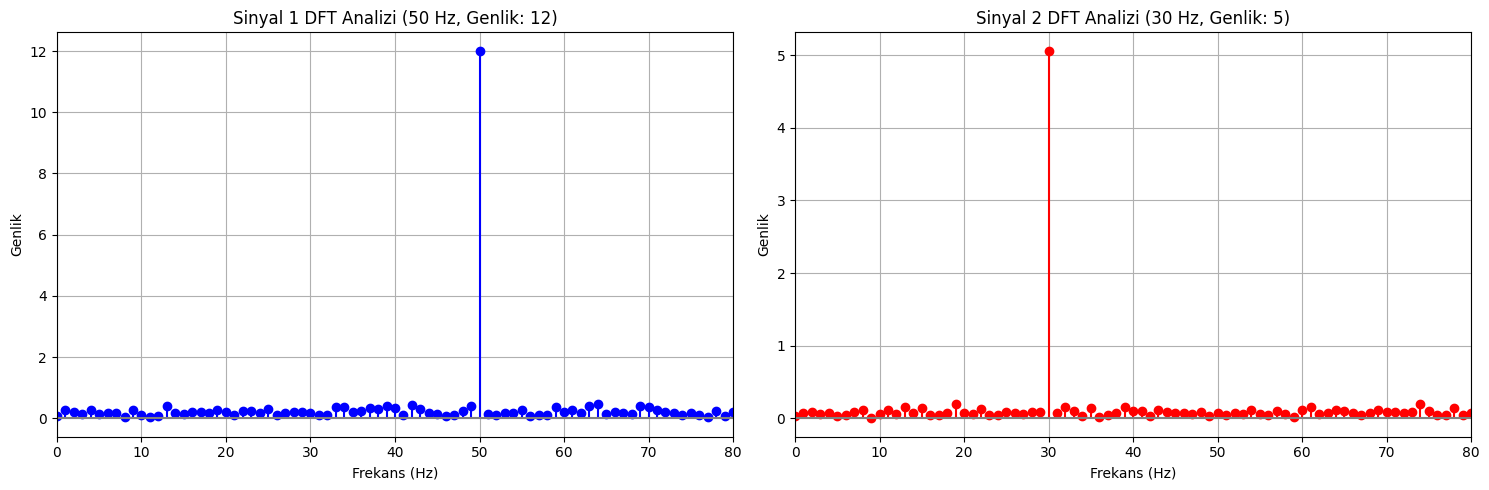

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# Zaman vektörünün ayarlanması
N = 512
fs = 512  # 512 Hz örnekleme frekansı
t = np.linspace(0, 1, N, endpoint=False)

# Sinyallerin üretilmesi
sinyal1_temiz = 12 * np.sin(2 * np.pi * 50 * t)
sinyal2_temiz = 5 * np.sin(2 * np.pi * 30 * t)

# Gürültü ekleme işlemi
gurultu1 = np.random.normal(0, 12 * 0.2, N)
gurultu2 = np.random.normal(0, 5 * 0.2, N)

sinyal1_gurultulu = sinyal1_temiz + gurultu1
sinyal2_gurultulu = sinyal2_temiz + gurultu2

# DFT katsayılarının ve harmoniklerinin hesaplanması
harmonik1 = dft_ve_harmonik_uret(sinyal1_gurultulu)
harmonik2 = dft_ve_harmonik_uret(sinyal2_gurultulu)

# Frekans ekseninin ayarlanması (Pozitif yarı)
yari_boyut = N // 2
frekans_ekseni = (np.arange(N) * (fs / N))[:yari_boyut]

# Ayrı ayrı DFT Sonuçlarının Görselleştirilmesi
plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.stem(frekans_ekseni, harmonik1[:yari_boyut], linefmt='blue', markerfmt='bo', basefmt='grey')
plt.title('Sinyal 1 DFT Analizi (50 Hz, Genlik: 12)')
plt.xlabel('Frekans (Hz)')
plt.ylabel('Genlik')
plt.xlim(0, 80)
plt.grid(True)

plt.subplot(1, 2, 2)
plt.stem(frekans_ekseni, harmonik2[:yari_boyut], linefmt='red', markerfmt='ro', basefmt='grey')
plt.title('Sinyal 2 DFT Analizi (30 Hz, Genlik: 5)')
plt.xlabel('Frekans (Hz)')
plt.ylabel('Genlik')
plt.xlim(0, 80)
plt.grid(True)

plt.tight_layout()
plt.show()

#### İki Sinyalin Toplanması ve Toplam Sinyalin Spektrumu

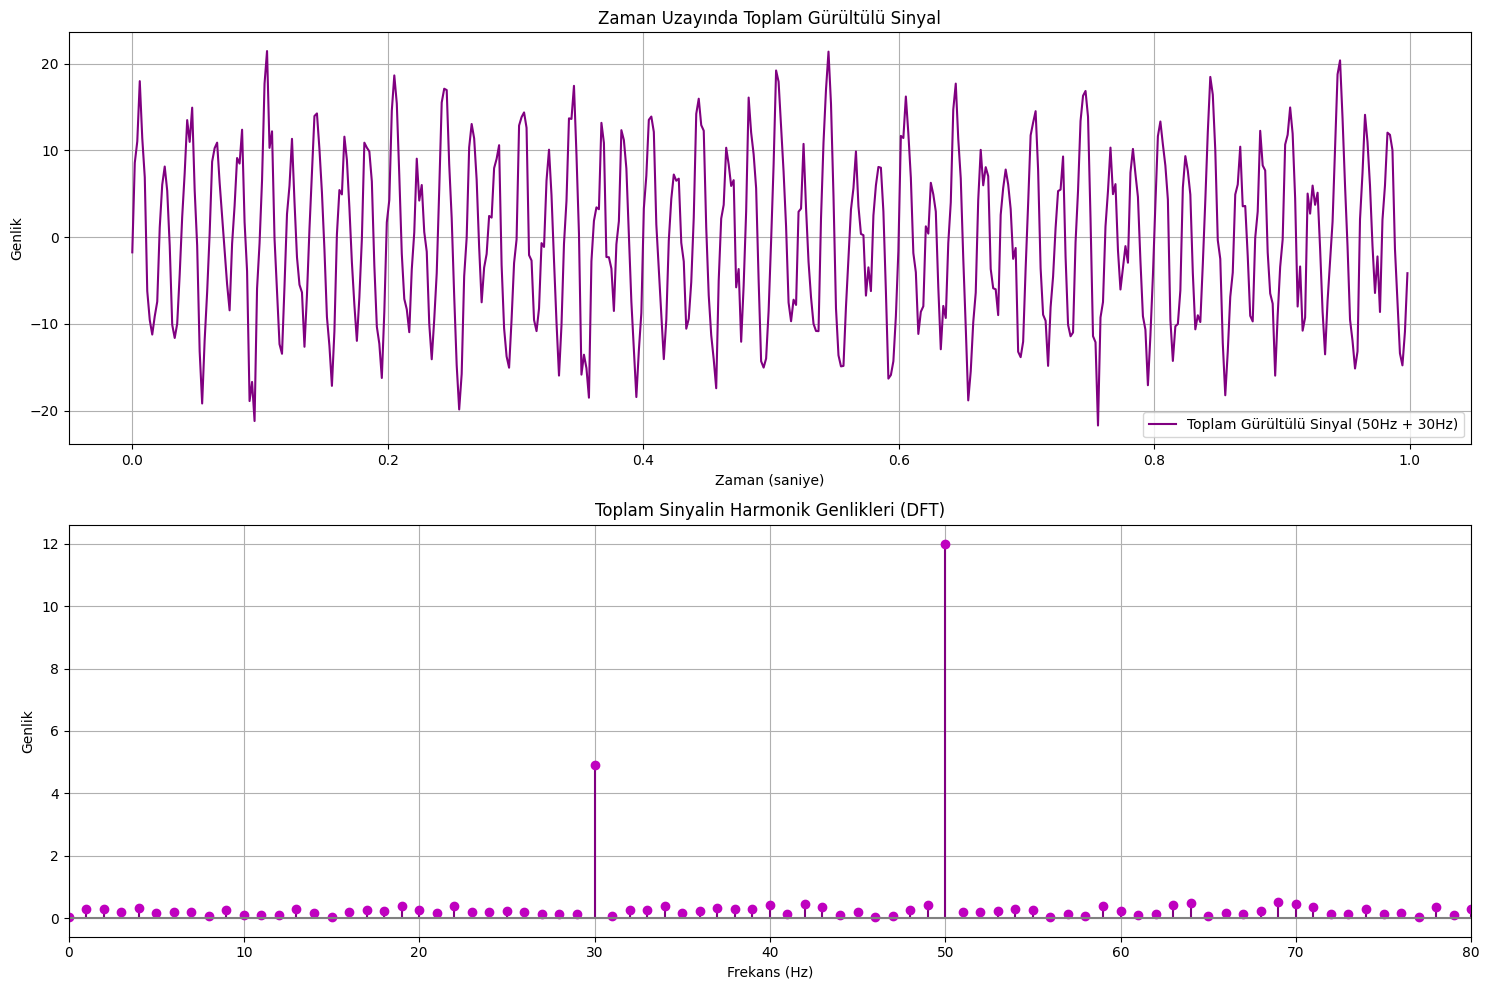

In [10]:
# İki gürültülü sinyalin toplanması
toplam_sinyal = sinyal1_gurultulu + sinyal2_gurultulu

# Toplam sinyalin DFT'si
harmonik_toplam = dft_ve_harmonik_uret(toplam_sinyal)

# Görselleştirme
plt.figure(figsize=(15, 10))

# Zaman Uzayında Toplam Sinyal
plt.subplot(2, 1, 1)
plt.plot(t, toplam_sinyal, color='purple', label='Toplam Gürültülü Sinyal (50Hz + 30Hz)')
plt.title('Zaman Uzayında Toplam Gürültülü Sinyal')
plt.xlabel('Zaman (saniye)')
plt.ylabel('Genlik')
plt.grid(True)
plt.legend()

# Frekans Uzayında Toplam Sinyalin Spektrumu
plt.subplot(2, 1, 2)
plt.stem(frekans_ekseni, harmonik_toplam[:yari_boyut], linefmt='purple', markerfmt='mo', basefmt='grey')
plt.title('Toplam Sinyalin Harmonik Genlikleri (DFT)')
plt.xlabel('Frekans (Hz)')
plt.ylabel('Genlik')
plt.xlim(0, 80)
plt.grid(True)

plt.tight_layout()
plt.show()

### 6. Frekans Filtresi ve IDFT ile Sinyal Rekonstrüksiyonu (Yeniden Üretim)

Frekans uzayında filtreleme yapmak için şu adımları takip edeceğiz:
1. Sinyalin kompleks DFT katsayılarını hesaplayacağız.
2. Belirlediğimiz eşik değerin altında kalan harmoniklerin genliklerini (ve ilgili kompleks katsayılarını) sıfırlayacağız.
3. Ters DFT (IDFT) formülünü ($x[n] = \frac{1}{N} \sum_{k=0}^{N-1} X[k] e^{j 2 \pi k n / N}$) uygulayarak sinyali zaman uzayına geri döndüreceğiz.

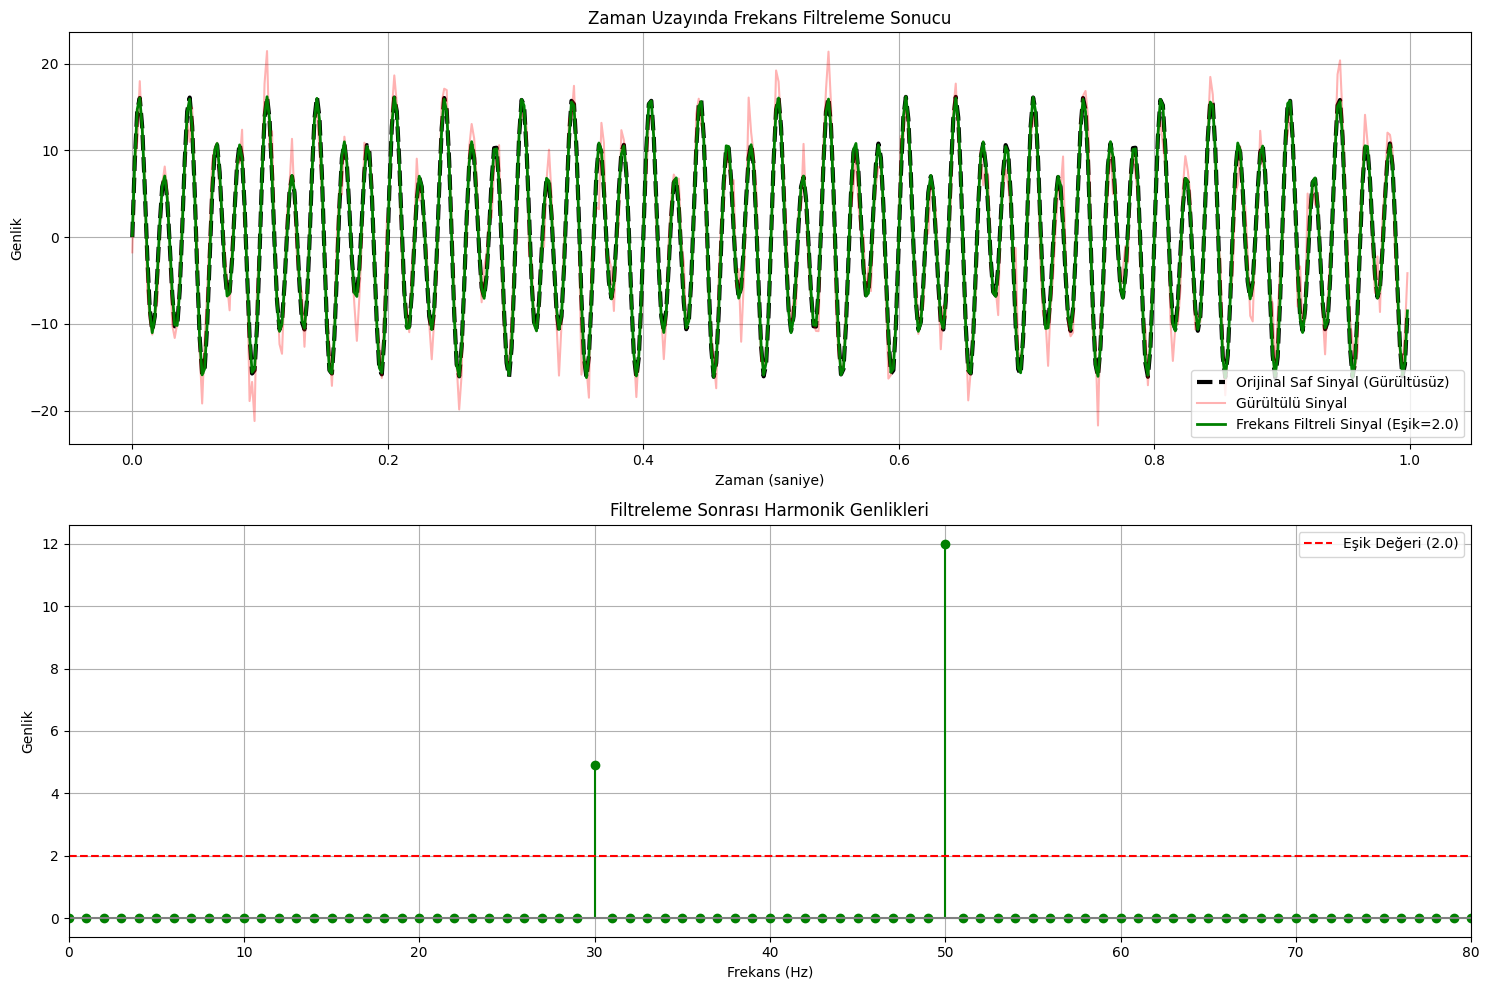

In [11]:
import numpy as np
import matplotlib.pyplot as plt

def idft_hesapla(dft_katsayilari):
    N = len(dft_katsayilari)
    n = np.arange(N)
    k = n.reshape((N, 1))
    ustel_terim = np.exp(2j * np.pi * k * n / N)
    # IDFT formülü gereği katsayılar toplamı N'e bölünür
    reconstructed_sinyal = np.dot(ustel_terim, dft_katsayilari) / N
    return np.real(reconstructed_sinyal)  # Sanal kısmı (sıfıra yakın) atıp reel kısmı alıyoruz

def frekans_esik_filtresi(sinyal, esik_degeri):
    N = len(sinyal)

    # 1. DFT katsayılarını hesaplayalım (Kompleks)
    n = np.arange(N)
    k = n.reshape((N, 1))
    ustel_terim = np.exp(-2j * np.pi * k * n / N)
    dft_katsayilari = np.dot(ustel_terim, sinyal)

    # Her bir frekans bileşeninin normalize genliğini bulalım
    genlikler = (2.0 / N) * np.abs(dft_katsayilari)

    # 2. Eşik değerin altında kalan frekans bileşenlerini sıfırlayalım
    filtreli_katsayilar = dft_katsayilari.copy()
    filtreli_katsayilar[genlikler < esik_degeri] = 0

    # 3. IDFT ile zaman uzayına geri dönelim
    temizlenmis_sinyal = idft_hesapla(filtreli_katsayilar)
    return temizlenmis_sinyal, filtreli_katsayilar

# Filtreleme testi için eşik değer belirliyoruz
# Sinyallerimizin genlikleri 12 ve 5 olduğundan, eşik değeri olarak 2.0 seçmek mantıklıdır
esik = 2.0
temizlenmis_toplam, filtreli_katsayilar = frekans_esik_filtresi(toplam_sinyal, esik)

# Filtrelenmiş Spektrum için Harmonik Vektör
harmonik_filtreli = (2.0 / N) * np.abs(filtreli_katsayilar)

# Sonuçların Görselleştirilmesi
plt.figure(figsize=(15, 10))

# Zaman Uzayında Karşılaştırma
plt.subplot(2, 1, 1)
plt.plot(t, sinyal1_temiz + sinyal2_temiz, label='Orijinal Saf Sinyal (Gürültüsüz)', color='black', linewidth=3, linestyle='--')
plt.plot(t, toplam_sinyal, label='Gürültülü Sinyal', color='red', alpha=0.3)
plt.plot(t, temizlenmis_toplam, label=f'Frekans Filtreli Sinyal (Eşik={esik})', color='green', linewidth=2)
plt.title('Zaman Uzayında Frekans Filtreleme Sonucu')
plt.xlabel('Zaman (saniye)')
plt.ylabel('Genlik')
plt.grid(True)
plt.legend()

# Filtrelenmiş Spektrum
plt.subplot(2, 1, 2)
plt.stem(frekans_ekseni, harmonik_filtreli[:yari_boyut], linefmt='green', markerfmt='go', basefmt='grey')
plt.axhline(y=esik, color='r', linestyle='--', label=f'Eşik Değeri ({esik})')
plt.title('Filtreleme Sonrası Harmonik Genlikleri')
plt.xlabel('Frekans (Hz)')
plt.ylabel('Genlik')
plt.xlim(0, 80)
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

### 7. 2-Boyutlu Ayrık Fourier Dönüşümü (2D DFT)

2D DFT, iki boyutlu bir matris (görüntü) üzerinde her satıra ve ardından her sütuna sırasıyla 1D DFT uygulanmasıyla elde edilebilir ($X_{2D} = \text{DFT}_{sütun}(\text{DFT}_{satır}(x))$). Yazacağımız fonksiyon bir görüntüyü girdi alıp frekans genlik spektrumunu hesaplayacaktır.

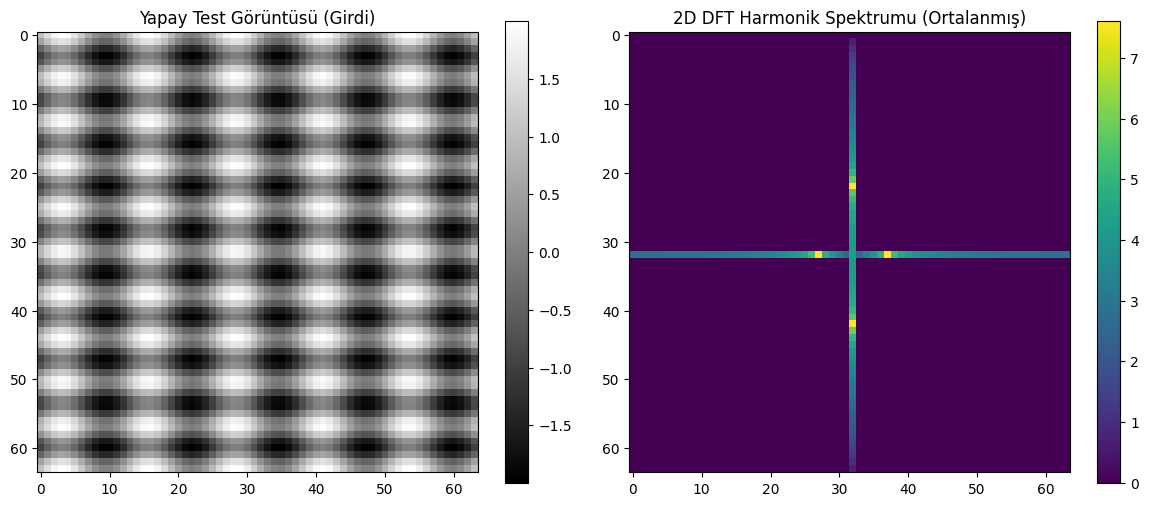

In [12]:
import numpy as np
import matplotlib.pyplot as plt

def dft_2d(görüntü):
    # Görüntü boyutlarını alalım
    M, N = görüntü.shape

    # Boyutların 2'nin kuvveti olduğunu basitçe varsayalım veya kontrol edelim
    # 1D DFT fonksiyonumuzu her satıra uygulayalım
    satir_dft = np.zeros((M, N), dtype=complex)

    # Satır bazında 1D DFT
    n_N = np.arange(N)
    k_N = n_N.reshape((N, 1))
    ustel_N = np.exp(-2j * np.pi * k_N * n_N / N)
    for i in range(M):
        satir_dft[i, :] = np.dot(ustel_N, görüntü[i, :])

    # Sütun bazında 1D DFT
    dft_2d_sonuc = np.zeros((M, N), dtype=complex)
    m_M = np.arange(M)
    l_M = m_M.reshape((M, 1))
    ustel_M = np.exp(-2j * np.pi * l_M * m_M / M)
    for j in range(N):
        dft_2d_sonuc[:, j] = np.dot(ustel_M, satir_dft[:, j])

    # Harmonik Vektör/Matris (Magnitude Spectrum)
    harmonik_2d = np.abs(dft_2d_sonuc)
    return harmonik_2d

# Test için yapay bir 2D desen/görüntü oluşturalım (64x64 boyutunda 2'nin kuvveti)
boyut = 64
x_ekseni = np.linspace(0, 1, boyut)
y_ekseni = np.linspace(0, 1, boyut)
X, Y = np.meshgrid(x_ekseni, y_ekseni)

# Hem yatay hem dikey dalga içeren bir desen oluşturuyoruz
yapay_resim = np.sin(2 * np.pi * 5 * X) + np.cos(2 * np.pi * 10 * Y)

# 2D DFT Hesaplama
harmonik_resim = dft_2d(yapay_resim)

# Alçak frekansları (merkezi) görsel olarak ortalamak için FFTShift işlemi simüle edilir
harmonik_kaydirilmis = np.fft.fftshift(harmonik_resim)

# Görselleştirme
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(yapay_resim, cmap='gray')
plt.title('Yapay Test Görüntüsü (Girdi)')
plt.colorbar()

plt.subplot(1, 2, 2)
# Detayları iyi görmek için logaritmik ölçekleme uygulanır
plt.imshow(np.log1p(harmonik_kaydirilmis), cmap='viridis')
plt.title('2D DFT Harmonik Spektrumu (Ortalanmış)')
plt.colorbar()

plt.tight_layout()
plt.show()

### 8. Görüntüye Gauss ve Tuz-Biber Gürültüsü Ekleme ve 2D Spektrum Analizi

Bu adımda görüntülerimize gürültü ekleyip, 2D DFT harmonik matrisleri (genlik spektrumları) üzerindeki etkilerini görselleştirerek analiz edeceğiz.

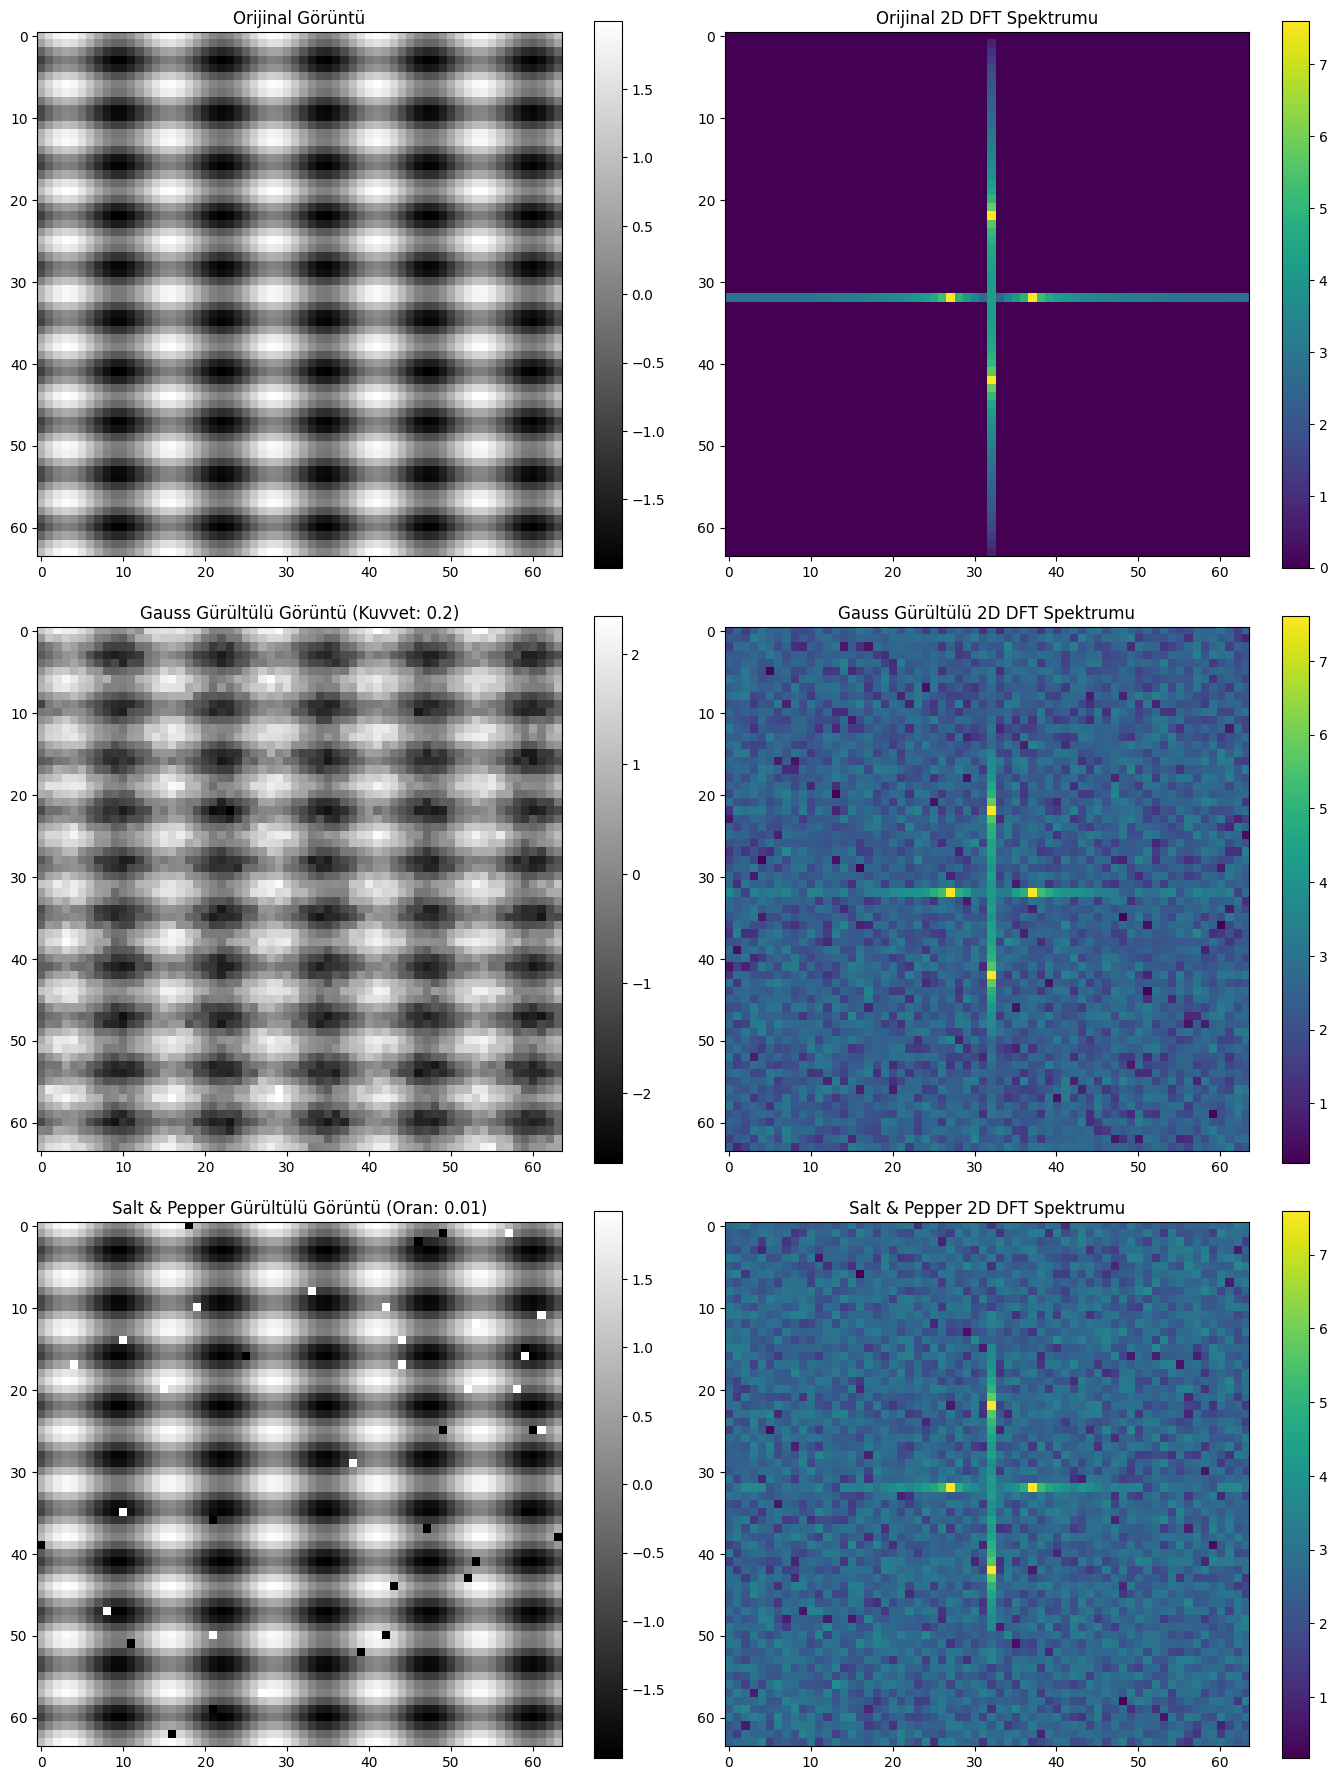

In [15]:
import numpy as np
import matplotlib.pyplot as plt

def gauss_gurultusu_ekle(resim, gurultu_kuvveti):
    # Resimle aynı boyutta standart normal dağılımlı gürültü üretip ölçekliyoruz
    gurultu = np.random.normal(0, gurultu_kuvveti, resim.shape)
    gurultulu_resim = resim + gurultu
    return gurultulu_resim

def salt_and_pepper_ekle(resim, gurultu_orani):
    gurultulu_resim = resim.copy()
    M, N = resim.shape

    # Toplam değiştirilecek piksel sayısını hesaplıyoruz
    toplam_piksel = M * N
    gurultulu_piksel_sayisi = int(toplam_piksel * gurultu_orani)

    # Rastgele koordinatlar seçiyoruz
    satir_indisleri = np.random.randint(0, M, gurultulu_piksel_sayisi)
    sutun_indisleri = np.random.randint(0, N, gurultulu_piksel_sayisi)

    # Seçilen piksellerin yarısını tuz (maksimum değer), yarısını biber (minimum değer) yapıyoruz
    min_val, max_val = resim.min(), resim.max()
    yari = gurultulu_piksel_sayisi // 2

    # Tuz ekleme
    for i in range(yari):
        gurultulu_resim[satir_indisleri[i], sutun_indisleri[i]] = max_val
    # Biber ekleme
    for i in range(yari, gurultulu_piksel_sayisi):
        gurultulu_resim[satir_indisleri[i], sutun_indisleri[i]] = min_val

    return gurultulu_resim

# Testleri gerçekleştirelim
gauss_kuvveti = 0.2
sp_orani = 0.01  # %10 oranında piksel bozulması

resim_gauss = gauss_gurultusu_ekle(yapay_resim, gauss_kuvveti)
resim_sp = salt_and_pepper_ekle(yapay_resim, sp_orani)

# 2D DFT Hesaplamaları
harmonik_gauss = dft_2d(resim_gauss)
harmonik_sp = dft_2d(resim_sp)

# FFTShift simülasyonları
harmonik_gauss_shift = np.fft.fftshift(harmonik_gauss)
harmonik_sp_shift = np.fft.fftshift(harmonik_sp)

# Görselleştirme ve Karşılaştırma
fig, axes = plt.subplots(3, 2, figsize=(14, 18))

# 1. Satır: Orijinal
axes[0, 0].imshow(yapay_resim, cmap='gray')
axes[0, 0].set_title('Orijinal Görüntü')
axes[0, 1].imshow(np.log1p(harmonik_kaydirilmis), cmap='viridis')
axes[0, 1].set_title('Orijinal 2D DFT Spektrumu')

# 2. Satır: Gauss
axes[1, 0].imshow(resim_gauss, cmap='gray')
axes[1, 0].set_title(f'Gauss Gürültülü Görüntü (Kuvvet: {gauss_kuvveti})')
axes[1, 1].imshow(np.log1p(harmonik_gauss_shift), cmap='viridis')
axes[1, 1].set_title('Gauss Gürültülü 2D DFT Spektrumu')

# 3. Satır: Salt and Pepper
axes[2, 0].imshow(resim_sp, cmap='gray')
axes[2, 0].set_title(f'Salt & Pepper Gürültülü Görüntü (Oran: {sp_orani})')
axes[2, 1].imshow(np.log1p(harmonik_sp_shift), cmap='viridis')
axes[2, 1].set_title('Salt & Pepper 2D DFT Spektrumu')

for r in range(3):
    for c in range(2):
        fig.colorbar(axes[r, c].images[0], ax=axes[r, c])

plt.tight_layout()
plt.show()

### 9. Güncellenmiş Görev: Doğrudan 2D IDFT ve Filtreli 2D IDFT Karşılaştırmalı Analizi

Bu hücrede:
1. Gürültülü görüntülerin 2D DFT katsayılarına **hiçbir filtre uygulamadan doğrudan** `idft_2d` uygulayacağız. Bu işlem bize matematiksel ters dönüşümün doğruluğunu ispatlayacaktır.
2. Ardından, alçak geçiren filtre uygulanmış katsayılara 2D IDFT uygulayarak temizlenmiş hallerini elde edeceğiz.
3. Orijinal temiz görüntü ile hem doğrudan geri dönüştürülmüş (gürültülü) hem de filtrelenmiş görüntülerin ZMNCC yakınlık değerlerini hesaplayıp kıyaslayacağız.

In [20]:
import numpy as np
import matplotlib.pyplot as plt

# 1. 2D IDFT Tanımlaması
def idft_2d(dft_matrisi):
    M, N = dft_matrisi.shape
    # Satır bazında 1D IDFT
    satir_idft = np.zeros((M, N), dtype=complex)
    n_N = np.arange(N)
    k_N = n_N.reshape((N, 1))
    ustel_N = np.exp(2j * np.pi * k_N * n_N / N)
    for i in range(M):
        satir_idft[i, :] = np.dot(ustel_N, dft_matrisi[i, :]) / N

    # Sütun bazında 1D IDFT
    idft_2d_sonuc = np.zeros((M, N), dtype=complex)
    m_M = np.arange(M)
    l_M = m_M.reshape((M, 1))
    ustel_M = np.exp(2j * np.pi * l_M * m_M / M)
    for j in range(N):
        idft_2d_sonuc[:, j] = np.dot(ustel_M, satir_idft[:, j]) / M

    return np.real(idft_2d_sonuc)

# 2. ZMNCC Benzerlik Hesaplama Tanımlaması
def zmncc_hesapla(resim1, resim2):
    mean1 = np.mean(resim1)
    mean2 = np.mean(resim2)
    r1_zero = resim1 - mean1
    r2_zero = resim2 - mean2
    pay = np.sum(r1_zero * r2_zero)
    payda = np.sqrt(np.sum(r1_zero ** 2) * np.sum(r2_zero ** 2))
    if payda == 0:
        return 0.0
    return pay / payda

# 3. 2D DFT Kompleks Hesaplama
def dft_2d_kompleks(görüntü):
    M, N = görüntü.shape
    satir_dft = np.zeros((M, N), dtype=complex)
    n_N = np.arange(N)
    k_N = n_N.reshape((N, 1))
    ustel_N = np.exp(-2j * np.pi * k_N * n_N / N)
    for i in range(M):
        satir_dft[i, :] = np.dot(ustel_N, görüntü[i, :])
    dft_2d_sonuc = np.zeros((M, N), dtype=complex)
    m_M = np.arange(M)
    l_M = m_M.reshape((M, 1))
    ustel_M = np.exp(-2j * np.pi * l_M * m_M / M)
    for j in range(N):
        dft_2d_sonuc[:, j] = np.dot(ustel_M, satir_dft[:, j])
    return dft_2d_sonuc

# 4. Frekans Filtresi Tanımlaması
def alcak_geciren_filtre_uygula(harmonik_ve_faz, kesim_frekansi):
    M, N = harmonik_ve_faz.shape
    cx, cy = M // 2, N // 2
    y, x = np.ogrid[-cx:M-cx, -cy:N-cy]
    maske = (x*x + y*y) <= (kesim_frekansi*kesim_frekansi)

    dft_shifted = np.fft.fftshift(harmonik_ve_faz)
    dft_shifted_filtrelenmis = dft_shifted * maske
    return np.fft.ifftshift(dft_shifted_filtrelenmis)

# Kompleks Frekans Katsayılarını ve Filtrelenmiş Spektrumları Yeniden Oluşturalım
comp_gauss = dft_2d_kompleks(resim_gauss)
comp_sp = dft_2d_kompleks(resim_sp)

kesim_r = 12
filtrelenmis_dft_gauss = alcak_geciren_filtre_uygula(comp_gauss, kesim_r)
filtrelenmis_dft_sp = alcak_geciren_filtre_uygula(comp_sp, kesim_r)

=== Gauss Gürültülü Görüntü ZMNCC Sonuçları ===
Doğrudan IDFT (Filtresiz) Benzerlik Skoru : 0.980701
Filtreli IDFT Benzerlik Skoru             : 0.996029

=== Salt & Pepper Gürültülü Görüntü ZMNCC Sonuçları ===
Doğrudan IDFT (Filtresiz) Benzerlik Skoru : 0.973315
Filtreli IDFT Benzerlik Skoru             : 0.995306


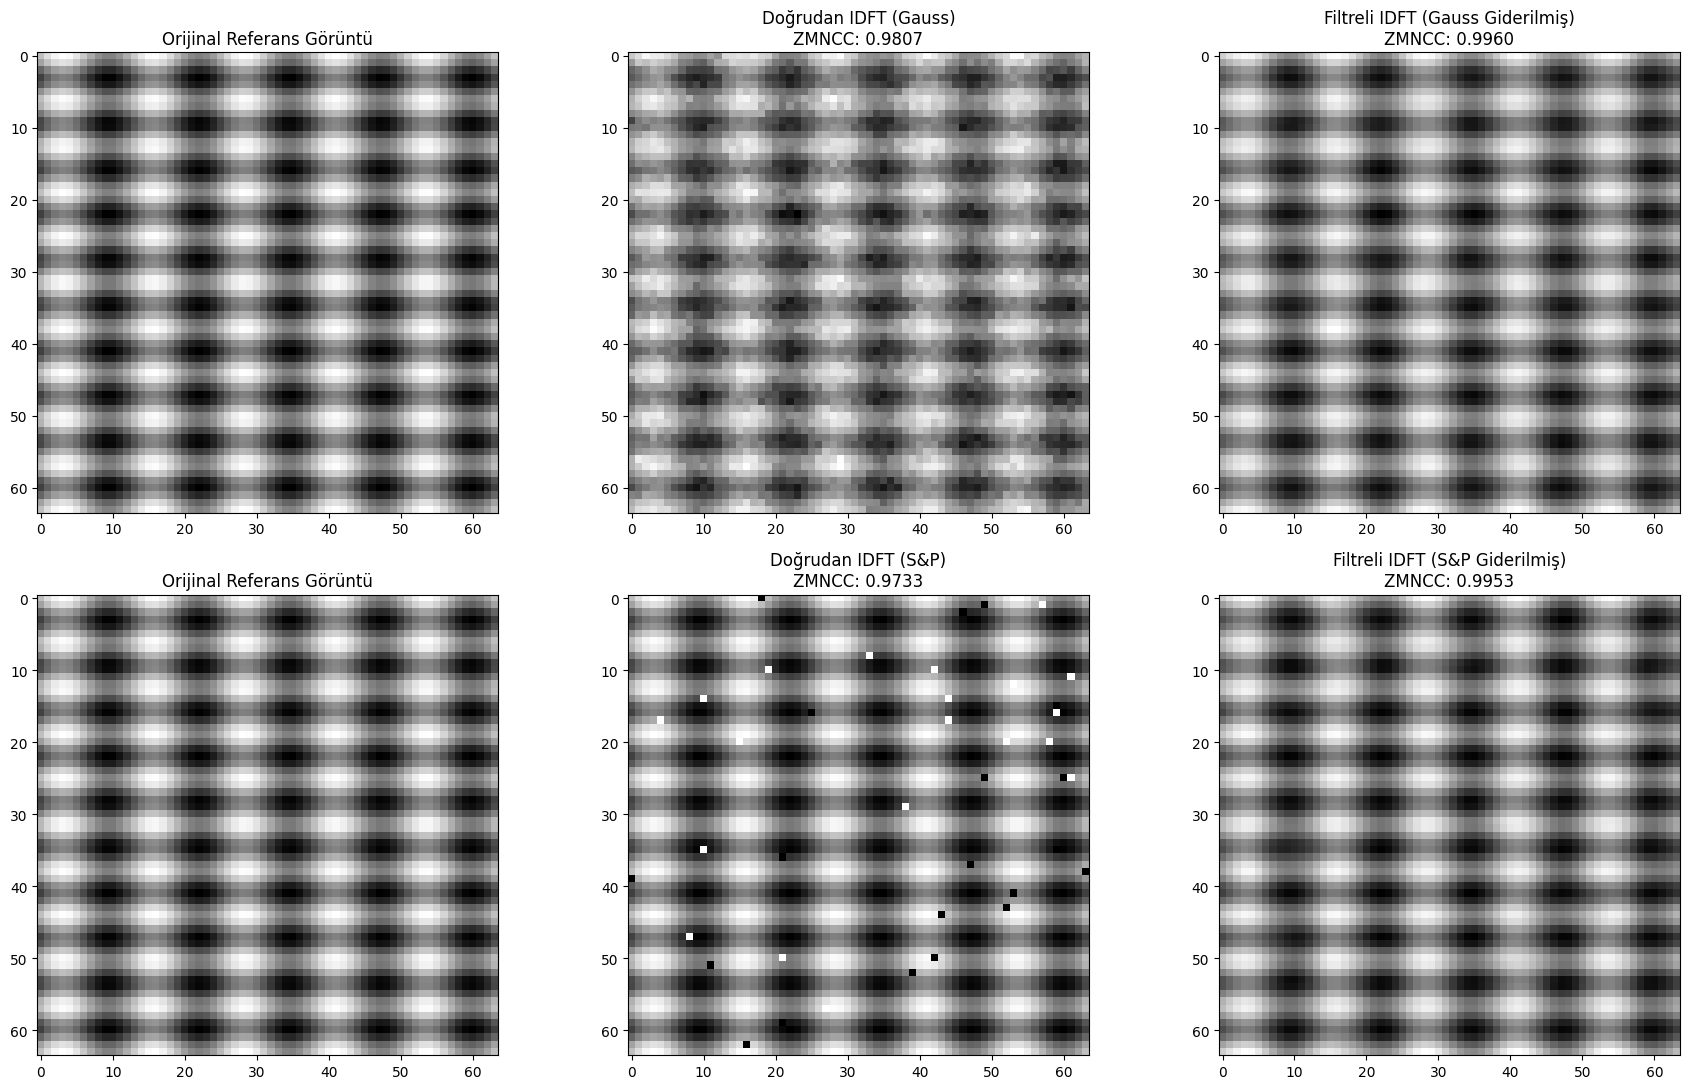

In [21]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Filtresiz Doğrudan IDFT (Kompleks katsayıların tamamını doğrudan IDFT'ye veriyoruz)
reconstructed_gauss_dogrudan = idft_2d(comp_gauss)
reconstructed_sp_dogrudan = idft_2d(comp_sp)

# 2. Filtreli IDFT (Daha önce tanımladığımız kesim yarıçaplı filtre çıktısı)
reconstructed_gauss_filtreli = idft_2d(filtrelenmis_dft_gauss)
reconstructed_sp_filtreli = idft_2d(filtrelenmis_dft_sp)

# 3. ZMNCC Benzerlik Hesaplamaları
# Orijinal vs Doğrudan Geri Dönüştürülmüş (Gürültülü) Görüntüler
zmncc_gauss_dogrudan = zmncc_hesapla(yapay_resim, reconstructed_gauss_dogrudan)
zmncc_sp_dogrudan = zmncc_hesapla(yapay_resim, reconstructed_sp_dogrudan)

# Orijinal vs Filtrelenmiş Geri Dönüştürülmüş Görüntüler
zmncc_gauss_filtreli = zmncc_hesapla(yapay_resim, reconstructed_gauss_filtreli)
zmncc_sp_filtreli = zmncc_hesapla(yapay_resim, reconstructed_sp_filtreli)

# Sonuçları Yazdıralım
print("=== Gauss Gürültülü Görüntü ZMNCC Sonuçları ===")
print(f"Doğrudan IDFT (Filtresiz) Benzerlik Skoru : {zmncc_gauss_dogrudan:.6f}")
print(f"Filtreli IDFT Benzerlik Skoru             : {zmncc_gauss_filtreli:.6f}")
print("\n=== Salt & Pepper Gürültülü Görüntü ZMNCC Sonuçları ===")
print(f"Doğrudan IDFT (Filtresiz) Benzerlik Skoru : {zmncc_sp_dogrudan:.6f}")
print(f"Filtreli IDFT Benzerlik Skoru             : {zmncc_sp_filtreli:.6f}")

# Görsel Karşılaştırma
fig, axes = plt.subplots(2, 3, figsize=(18, 11))

# Orijinal
axes[0, 0].imshow(yapay_resim, cmap='gray')
axes[0, 0].set_title('Orijinal Referans Görüntü')
axes[1, 0].imshow(yapay_resim, cmap='gray')
axes[1, 0].set_title('Orijinal Referans Görüntü')

# Doğrudan Dönüşüm (Noisy)
axes[0, 1].imshow(reconstructed_gauss_dogrudan, cmap='gray')
axes[0, 1].set_title(f'Doğrudan IDFT (Gauss)\nZMNCC: {zmncc_gauss_dogrudan:.4f}')
axes[1, 1].imshow(reconstructed_sp_dogrudan, cmap='gray')
axes[1, 1].set_title(f'Doğrudan IDFT (S&P)\nZMNCC: {zmncc_sp_dogrudan:.4f}')

# Filtreli Dönüşüm (Denoised)
axes[0, 2].imshow(reconstructed_gauss_filtreli, cmap='gray')
axes[0, 2].set_title(f'Filtreli IDFT (Gauss Giderilmiş)\nZMNCC: {zmncc_gauss_filtreli:.4f}')
axes[1, 2].imshow(reconstructed_sp_filtreli, cmap='gray')
axes[1, 2].set_title(f'Filtreli IDFT (S&P Giderilmiş)\nZMNCC: {zmncc_sp_filtreli:.4f}')

plt.tight_layout()
plt.show()

### 10. Gelişmiş Frekans Filtreleri (Low-Pass, High-Pass, Band-Pass, Band-Reject) ve ZMNCC Analizi

Bu bölümde ideal filtre formülasyonlarını kullanarak gürültülü görüntüler üzerinde aşağıdaki işlemleri uyguluyoruz:
* **Low-Pass Filter (LPF)**: Alçak frekansları geçirir, yüksek frekansları engeller. Gürültüyü azaltır ancak kenarları yumuşatır.
* **High-Pass Filter (HPF)**: Yüksek frekansları geçirir, alçak frekansları (ve DC bileşenini) engeller. Kenarları tespit eder ancak gürültüyü artırır ve ortalama parlaklığı yok eder.
* **Band-Pass Filter (BPF)**: Belirli bir frekans bandını geçirir. Sadece o frekans aralığındaki örüntüleri yakalar.
* **Band-Reject Filter (BRF)**: Belirli bir gürültülü frekans bandını söndürürken diğer tüm detayları muhafaza eder.

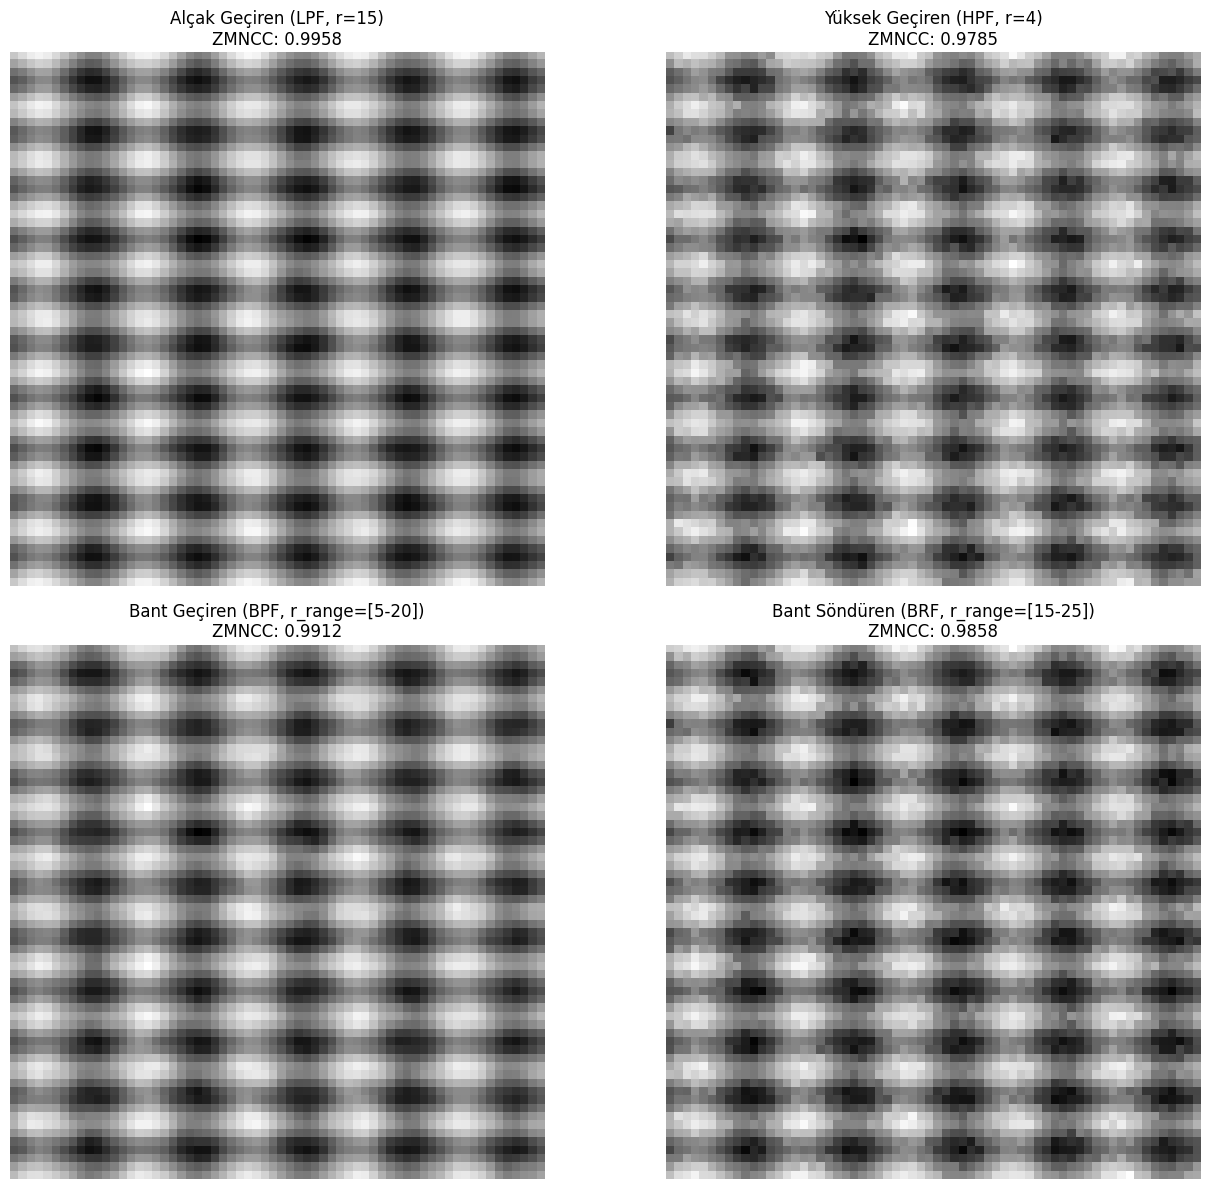

In [22]:
import numpy as np
import matplotlib.pyplot as plt

def frekans_filtre_tasarla(boyut, filtre_tipi, r_ic, r_dis=None):
    """Ideal dairesel frekans filtresi maskesi tasarlar (fftshift uyumlu)."""
    M, N = boyut, boyut
    cx, cy = M // 2, N // 2
    y, x = np.ogrid[-cx:M-cx, -cy:N-cy]
    mesafe_kare = x*x + y*y

    if filtre_tipi == 'low_pass':
        maske = mesafe_kare <= (r_ic * r_ic)
    elif filtre_tipi == 'high_pass':
        maske = mesafe_kare > (r_ic * r_ic)
    elif filtre_tipi == 'band_pass':
        assert r_dis is not None, "Band-pass için dış yarıçap (r_dis) belirtilmelidir."
        maske = (mesafe_kare >= (r_ic * r_ic)) & (mesafe_kare <= (r_dis * r_dis))
    elif filtre_tipi == 'band_reject':
        assert r_dis is not None, "Band-reject için dış yarıçap (r_dis) belirtilmelidir."
        maske = ~((mesafe_kare >= (r_ic * r_ic)) & (mesafe_kare <= (r_dis * r_dis)))
    else:
        raise ValueError("Geçersiz filtre tipi!")

    return maske

def dft_filtrele_ve_rekonst_et(dft_kompleks, maske):
    """DFT katsayılarına maskeyi merkezde (shift edilmiş halde) uygulayıp IDFT ile geri döndürür."""
    dft_shifted = np.fft.fftshift(dft_kompleks)
    dft_shifted_filtrelenmis = dft_shifted * maske
    dft_back = np.fft.ifftshift(dft_shifted_filtrelenmis)
    return idft_2d(dft_back)

# Filtre Parametreleri
r_lpf = 15
r_hpf = 4
r_bpf_ic, r_bpf_dis = 5, 20
r_brf_ic, r_brf_dis = 15, 25

# Maskelerin Oluşturulması (64x64)
maske_lpf = frekans_filtre_tasarla(boyut, 'low_pass', r_lpf)
maske_hpf = frekans_filtre_tasarla(boyut, 'high_pass', r_hpf)
maske_bpf = frekans_filtre_tasarla(boyut, 'band_pass', r_bpf_ic, r_bpf_dis)
maske_brf = frekans_filtre_tasarla(boyut, 'band_reject', r_brf_ic, r_brf_dis)

# Filtreleme Uygulaması (Örnek olarak Gauss Gürültülü Görüntü üzerinde çalışıyoruz)
img_lpf = dft_filtrele_ve_rekonst_et(comp_gauss, maske_lpf)
img_hpf = dft_filtrele_ve_rekonst_et(comp_gauss, maske_hpf)
img_bpf = dft_filtrele_ve_rekonst_et(comp_gauss, maske_bpf)
img_brf = dft_filtrele_ve_rekonst_et(comp_gauss, maske_brf)

# ZMNCC Benzerlik Hesaplamaları (Temiz Orijinal Görüntü Referans Alınarak)
z_lpf = zmncc_hesapla(yapay_resim, img_lpf)
z_hpf = zmncc_hesapla(yapay_resim, img_hpf)
z_bpf = zmncc_hesapla(yapay_resim, img_bpf)
z_brf = zmncc_hesapla(yapay_resim, img_brf)

# Görselleştirme Paneli
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# Low-Pass
axes[0, 0].imshow(img_lpf, cmap='gray')
axes[0, 0].set_title(f'Alçak Geçiren (LPF, r={r_lpf})\nZMNCC: {z_lpf:.4f}')

# High-Pass
axes[0, 1].imshow(img_hpf, cmap='gray')
axes[0, 1].set_title(f'Yüksek Geçiren (HPF, r={r_hpf})\nZMNCC: {z_hpf:.4f}')

# Band-Pass
axes[1, 0].imshow(img_bpf, cmap='gray')
axes[1, 0].set_title(f'Bant Geçiren (BPF, r_range=[{r_bpf_ic}-{r_bpf_dis}])\nZMNCC: {z_bpf:.4f}')

# Band-Reject
axes[1, 1].imshow(img_brf, cmap='gray')
axes[1, 1].set_title(f'Bant Söndüren (BRF, r_range=[{r_brf_ic}-{r_brf_dis}])\nZMNCC: {z_brf:.4f}')

for ax in axes.flat:
    ax.axis('off')

plt.tight_layout()
plt.show()

### 10. Görüntü Benzerliği Karşılaştırma Metrikleri Raporu

Görüntü işleme ve bilgisayarlı görü alanında iki piksel matrisinin yakınlığını/benzerliğini ölçmek için kullanılan başlıca metrikler ve karşılaştırmaları aşağıda sunulmuştur:

| Metrik | Çalışma İlkesi | Avantajları | Dezavantajları |
| :--- | :--- | :--- | :--- |
| **ZMNCC (Zero-Mean Normalized Cross-Correlation)** | Piksellerin ortalamasını çıkarıp standart sapmaya bölerek normalize eder ve korelasyonunu ölçer. $[-1, 1]$ arası değer üretir. | Parlaklık (bias) ve kontrast (gain) değişimlerine karşı tamamen duyarsızdır (dayanıklıdır). | Geometrik bozulmalara (dönme, ölçekleme vb.) karşı aşırı hassastır. Hesaplama maliyeti görece yüksektir. |
| **MSE (Mean Squared Error)** | Piksel bazında farkların karelerinin ortalamasını alır. $0$ değeri mükemmel benzerliği belirtir. | Matematiksel olarak türevi alınabilir, hesaplanması son derece basit ve hızlıdır. | İnsan gözünün algısal kalitesiyle uyuşmaz. Basit bir parlaklık kaymasında bile çok yüksek hata üretebilir. |
| **PSNR (Peak Signal-to-Noise Ratio)** | Maksimum piksel gücünün hata gücüne (MSE) logaritmik oranıdır (dB cinsinden). | Sinyal sıkıştırma ve gürültü seviyelerini dB ölçeğinde karşılaştırmak için standartlaşmış kolay bir yöntemdir. | Tıpkı MSE gibi piksellerin uzamsal (spatial) ilişkilerini dikkate almaz; insan gözünün algıladığı yapısal benzerliği yansıtmaz. |
| **SSIM (Structural Similarity Index)** | İnsan görsel sistemine uygun olarak görüntüdeki parlaklık, kontrast ve yapısal (korelasyon) bilgileri ayrı ayrı karşılaştırır. $[0, 1]$ arası değer üretir. | İnsan gözünün algısal kalitesine en yakın sonucu verir. Yapısal bozulmaları çok iyi yakalar. | Formülü diğer metriklere göre daha karmaşıktır ve hesaplama süresi uzundur. |

### Frekans Filtreleme Sonuçlarının Analizi ve Yorumu

* **Frekans Spektrumu Grafiği:** `esik = 2.0` değerinin altında kalan tüm gürültü frekansları sıfırlanmıştır. Geriye sadece genliği bu eşiğin üzerinde olan **30 Hz (Genlik: ~5)** ve **50 Hz (Genlik: ~12)** bileşenleri kalmıştır.
* **Zaman Uzayındaki Grafik:** Filtrelenmiş sinyal (yeşil çizgi), orijinal gürültüsüz siyah kesikli çizgiyi neredeyse mükemmel bir şekilde takip etmektedir. Frekans uzayında gürültü bileşenlerini tamamen sıfırladığımız için zaman uzayındaki gürültü de kusursuza yakın bir şekilde temizlenmiştir.